# MNIST Data Experiments

## 3rd party source

MNIST Dataset retrieved from

* https://git-disl.github.io/GTDLBench/datasets/mnist_datasets/
* https://drive.google.com/file/d/11ZiNnV3YtpZ7d9afHZg0rtDRrmhha-1E/view

This will include the following files:

In [5]:
import os

os.listdir('./mnist/MNIST_ORG')

['t10k-images.idx3-ubyte',
 't10k-labels.idx1-ubyte',
 'train-images.idx3-ubyte',
 'train-labels.idx1-ubyte']

* Color is Grey-scale
* Sample Size is 28x28

In [9]:
"""Installing numpy and matplotlib."""
%uv add numpy matplotlib
%pip install numpy matplotlib


Note: you may need to restart the kernel to use updated packages.


Resolved 12 packages in 1ms
Audited 11 packages in 1ms


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
import numpy as np
import matplotlib.pyplot as plt
"""Trying to import numpy and matplotlib.

mind you might have to restart the kernel after installing the packages and before importing them."""

'Trying to import numpy and matplotlib.\n\nmind you might have to restart the kernel after installing the packages and before importing them.'

Magic number, Data type unsigned byte (higher byte): 0x8
Magic number, Pixel uses 3 bytes per pixel (lower byte): 0x3
Number of images: 10000


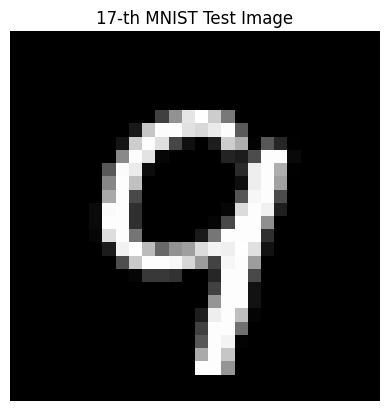

Image shape: (28, 28)


In [29]:
# Load the n-th image from the MNIST test images file and display it

def load_mnist_images(filename, idx):
    with open(filename, 'rb') as f:
        magic = int.from_bytes(f.read(4), 'big')
        print(f"Magic number, Data type unsigned byte (higher byte): {hex(magic >> 8)}")
        print(f"Magic number, Pixel uses 3 bytes per pixel (lower byte): {hex(magic & 0xFF)}")
        assert (magic & 0xFF) == 0x03, "Pixel data uses 3 bytes per pixel, expected 0x03"
        assert (magic >> 8) == 0x08, "Expected unsigned byte data type (0x08)"
        num_images = int.from_bytes(f.read(4), 'big')
        print(f"Number of images: {num_images}")
        rows = int.from_bytes(f.read(4), 'big')
        cols = int.from_bytes(f.read(4), 'big')
        # Skip to the desired image
        f.seek(16 + idx * rows * cols)
        img = np.frombuffer(f.read(rows * cols), dtype=np.uint8).reshape((rows, cols))
    return img

n = 16  # index of the image to load (0-based)
img_path = './mnist/MNIST_ORG/t10k-images.idx3-ubyte'
nth_img = load_mnist_images(img_path, n)  # index n is the n-th image

plt.imshow(nth_img, cmap='gray')
plt.title(f'{n+1}-th MNIST Test Image')
plt.axis('off')
plt.show()
print(f"Image shape: {nth_img.shape}")

In [36]:
def load_mnist_label(filename, idx):
    with open(filename, 'rb') as f:
        magic = int.from_bytes(f.read(4), 'big')
        num_labels = int.from_bytes(f.read(4), 'big')
        print(f"Magic number: {hex(magic)}, Number of labels: {num_labels}")
        f.seek(8 + idx)
        label = int.from_bytes(f.read(1), 'big')
    return label

n=16  # index of the label to load (0-based)
label_path = './mnist/MNIST_ORG/t10k-labels.idx1-ubyte'
nth_label = load_mnist_label(label_path, n)
print(f"Label for image {n+1}: {nth_label}")

Magic number: 0x801, Number of labels: 10000
Label for image 17: 9


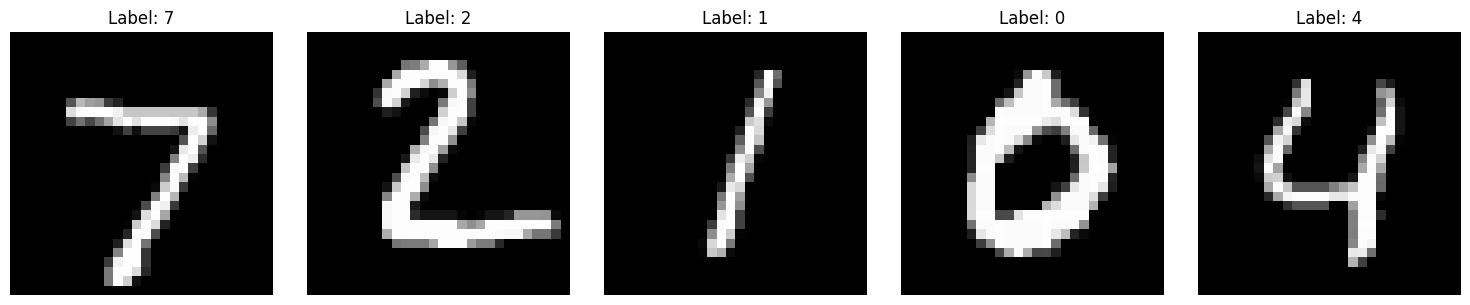

In [19]:
"""Display the first 5 images and their labels from the MNIST test set."""
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i in range(5):
    img = load_mnist_images(img_path, i)
    label = load_mnist_label(label_path, i)
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(f'Label: {label}')
    axes[i].axis('off')
plt.tight_layout()
plt.show()